# 4. Model CNN-SVM

Model má dve časti, ktoré sa trénujú oddelene:
1. **CNN** (ResNet18 z notebooku 2) prevedie každú snímku na 512 príznakov,
2. **SVM** (support vector machine) sa učí oddeliť triedy v priestore príznakov.

SVM potrebuje jeden vektor na klip, preto príznaky 16 snímok **spriemerujeme v čase**.
Poradie snímok sa tým stráca – model vidí, *čo* je v klipe, ale nie *ako sa to hýbe*.

**Protokol hodnotenia** (rovnaký pre všetky modely):
- 10 delení train/test podľa zdroja (film / človek),
- v každom delení sa kernel (lineárny / RBF) a hyperparametre vyberú 5-násobnou krížovou
  validáciou **iba na trénovacích dátach**, test sa použije len na finálne hodnotenie,
- hlavná metrika je **balanced accuracy** (priemer recall oboch tried), lebo triedy sú
  nevyvážené; model, ktorý by vždy povedal väčšinovú triedu, má balanced accuracy 0,5,
- výsledky zvlášť pre testovacie klipy z HMDB51 a z Charades (`test_set`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from har_utils import CLASSES, evaluate_svm, summarize

df = pd.read_csv("index.csv")
feats = np.load("features_resnet.npy")     # (klipy, 16, 512)
X = feats.mean(axis=1)                     # priemer v čase -> (klipy, 512)
print(X.shape)

(238, 512)


In [2]:
results, y_all, p_all = evaluate_svm(X, df)

Path("results").mkdir(exist_ok=True)
results.to_csv("results/cnn_svm.csv", index=False)
print(summarize(results, "CNN-SVM").to_string())

                            acc        bal_acc             f1
model   test_set                                             
CNN-SVM hmdb      0.868 ± 0.066  0.878 ± 0.062  0.865 ± 0.067


## Chyby modelu

Confusion matrix je súčtom testovacích predikcií zo všetkých 10 delení.

              precision    recall  f1-score   support

         eat       0.79      0.94      0.86       332
        clap       0.94      0.81      0.87       444

    accuracy                           0.86       776
   macro avg       0.87      0.87      0.86       776
weighted avg       0.88      0.86      0.87       776



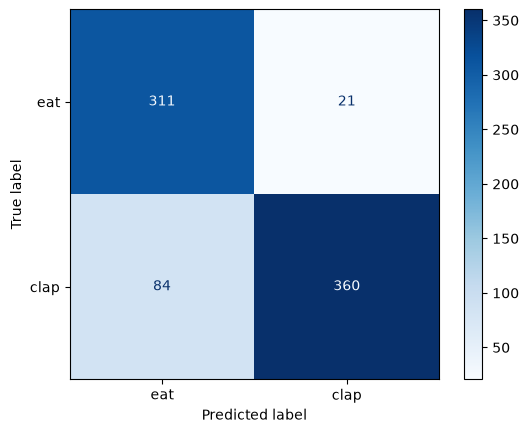

In [3]:
print(classification_report(y_all, p_all, target_names=CLASSES))
ConfusionMatrixDisplay.from_predictions(y_all, p_all, display_labels=CLASSES, cmap="Blues");